In [1]:
# import libs
import os 
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import sys
import scanpy as sc 
import pandas as pd 
import numpy as np 
import anndata as ad
import matplotlib.pyplot as plt 
import matplotlib.patches as mpatches
from matplotlib.path import Path
import numpy as np
import seaborn as sns
import matplotlib.pyplot as safe_plt
import pymn

In [2]:
env_path = "../.env"
# call paths from .env
if os.path.exists(env_path):
    with open(env_path) as f:
        os.environ.update(
            line.strip().split("=", 1) for line in f
            if line.strip() and not line.startswith("#")
        )
        
plots_dir = os.getenv("PLOTS_DIR")
processed_adata_dir = os.getenv("PROCESSED_ANNDATA_DIR")
src_dir = os.getenv("SRC_DIR")

In [3]:
# load the original anndata
adata = sc.read_h5ad(processed_adata_dir + "Adata_subclustered.h5ad")

In [4]:
# convert to str
adata.obs['leiden_subclustered_G1 RG'] = adata.obs['leiden_subclustered_G1 RG'].astype(str)
adata.obs['dataset_of_origin'] = adata.obs['dataset_of_origin'].astype(str)

In [5]:
# remove mouse dataset
adata_ss = adata[~adata.obs['species'].isin(['mouse_ncx'])].copy()

In [6]:
# compute hvgs
pymn.variableGenes(adata_ss, study_col='dataset_of_origin')

In [7]:
# print number of hvgs
num_true = adata_ss.var['highly_variable'].sum()
print(num_true)

536


In [8]:
# compute metaneighbors
pymn.MetaNeighborUS(adata_ss,
                    study_col='dataset_of_origin',
                    ct_col='leiden_subclustered_G1 RG',
                    fast_version=True)

/usr/local/lib/python3.10/dist-packages/seaborn/matrix.py:1124: UserWarning: ``square=True`` ignored in clustermap
  warnings.warn(msg)


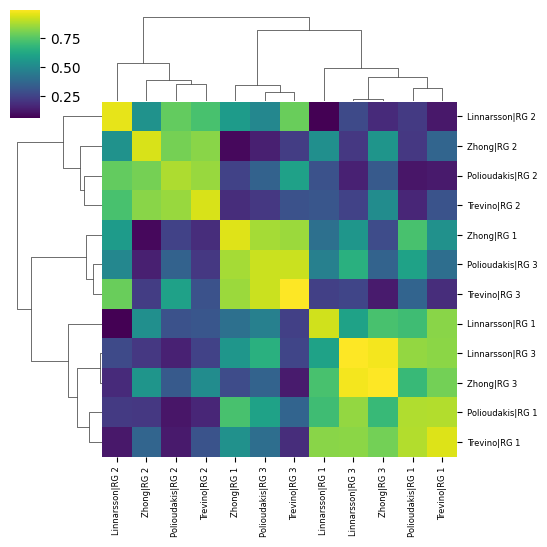

In [9]:
# plot a heatmap
plt_1 = pymn.plotMetaNeighborUS(adata_ss, cmap='viridis', show = False)
plt_1.savefig(plots_dir + 'clustering/Metaneighbor_RG_plot.png', dpi = 300, bbox_inches = 'tight')

In [10]:
# show topHits
pymn.topHits(adata_ss, threshold=0.8)

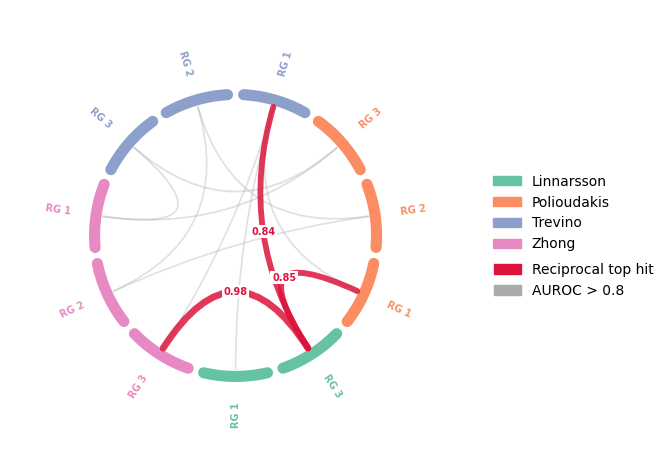

In [11]:
# plot chord graph
script_path = src_dir + 'plot_chord.py'
%run -i $script_path
plot_chord(adata_ss, save_path=plots_dir + 'cluster_similarity')